# Segmenter les clients d'Olist pour cibler les campagnes marketing
## Partie 2 : Modélisation et choix de la segmentation

### Sommaire <a class="anchor" id="sommaire"></a>

* [Introduction](#0)
* [Chargement des données](#1)
* [Une première approche simple : les scores RFM](#2)
* [K-Means](#3)
    * [Essai 1 : Récence, Fréquence, Montant](#3_1)
    * [Essai 2 : RFM + note moyenne](#3_2)
    * [Essai 3 : RFM + note moyenne + nombre de produits](#3_3)
    * [Essai 4 : logarithme du RFM](#3_4)
* [DBSCAN](#4)
* [Classification ascendante hiérarchique (CAH)](#5)
* [Choix du modèle](#6)
* [Stabilité du modèle retenu](#7)
* [Conclusion](#8)

## Introduction <a class="anchor" id="0"></a>
Le notebook 1 a décrit chaque client par ses indicateurs **RFM** (Récence, Fréquence, Montant).
Ce deuxième notebook cherche la **meilleure façon de regrouper les clients** en segments utiles pour le marketing.

Un bon modèle doit remplir deux conditions :
- **techniquement**, des groupes bien séparés (mesurés par le **score de silhouette**) ;
- **pour le métier**, des groupes **équilibrés** et **faciles à interpréter**.

## Chargement des données <a class="anchor" id="1"></a>

On lit le fichier `rfm.csv`, produit par le notebook 1 : une ligne par client, avec sa récence,
sa fréquence et son montant.

In [1]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Mesure du temps d'exécution des algorithmes
from time import time

# Style commun à tous les graphiques
sns.set_theme(style="whitegrid", palette="bright")

# Fichier produit par le notebook 1 : une ligne par client
rfm = pd.read_csv('data/rfm.csv')

print(f"{rfm.shape[0]:,} clients")
rfm.head()

94,989 clients


,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,116,1,141.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,119,1,27.19
2,0000f46a3911fa3c0805444483337064,542,1,86.22
3,0000f6ccb0745a6a4b88665a16c9f078,326,1,43.62
4,0004aac84e0df4da2b147fca70cf8255,293,1,196.89


<a href="#sommaire" rev="footnote">&#8617;</a>

## Une première approche simple : les scores RFM <a class="anchor" id="2"></a>

La **segmentation RFM** est une méthode classique du marketing : elle classe les clients selon
la **date de leur dernier achat** (Récence), le **nombre de leurs achats** (Fréquence) et
le **total qu'ils ont dépensé** (Montant). Pour en savoir plus :
[Segmentez votre base clients (OpenClassrooms)](https://openclassrooms.com/fr/courses/4762856-analysez-des-donnees-marketing/5525761-segmentez-votre-base-clients).

Avant d'utiliser le machine learning, on applique cette méthode telle quelle :
on donne à chaque client une **note** pour chaque indicateur, puis on les additionne.
- **Récence** : les 20 % de clients les plus récents ont 5, les 20 % les plus anciens ont 1 ;
- **Montant** : les 20 % qui dépensent le plus ont 5, les 20 % qui dépensent le moins ont 1 ;
- **Fréquence** : 1 pour une commande, 2 pour deux commandes, 3 au-delà. On ne peut pas utiliser
  de quintiles, puisque 97 % des clients n'ont passé qu'une commande.

Le score total (de 3 à 13) permet ensuite de répartir les clients en **5 segments**.
Cette approche servira de **point de comparaison** pour les modèles de clustering.

In [2]:
scores = rfm.copy()

# pd.qcut découpe une variable en 5 groupes de même effectif (quintiles)
# Récence : plus elle est faible, meilleur est le score, d'où les étiquettes inversées
scores['R_score'] = pd.qcut(scores['Recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
scores['M_score'] = pd.qcut(scores['Monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# Fréquence : 1, 2, ou 3 pour 3 commandes et plus
scores['F_score'] = scores['Frequency'].clip(upper=3)

# Score total (de 3 à 13), puis 5 segments de taille proche
scores['RFM_score'] = scores['R_score'] + scores['F_score'] + scores['M_score']
scores['Segment'] = pd.qcut(scores['RFM_score'], q=5,
                            labels=['Group1', 'Group2', 'Group3', 'Group4', 'Group5'])

# Profil moyen et nombre de clients de chaque segment
profil = scores.groupby('Segment', observed=True)[['Recency', 'Frequency', 'Monetary']].mean().round(1)
profil['Nombre de clients'] = scores['Segment'].value_counts()
profil

,Recency,Frequency,Monetary,Nombre de clients
Segment,,,,
Group1,384.0,1.0,61.5,23279
Group2,263.4,1.0,132.9,32810
Group3,188.5,1.0,199.3,15139
Group4,141.7,1.1,223.8,11448
Group5,86.6,1.1,354.7,12313


**À retenir :** les 5 segments sont **bien ordonnés** : du Group1 au Group5, les clients sont
de plus en plus **récents** (de 384 à 87 jours en moyenne) et dépensent de plus en plus
(de 62 à 355 réals). Cette approche a toutefois trois limites :
- la **fréquence ne distingue presque personne** : elle vaut environ 1 dans tous les segments,
  puisque 97 % des clients n'ont passé qu'une commande ;
- les segments sont **de tailles inégales** (de 11 448 à 32 810 clients), car le score total
  ne prend que quelques valeurs : beaucoup de clients ont le même score ;
- les clients sont seulement **classés du moins bon au meilleur**. Un client qui a beaucoup
  dépensé il y a longtemps et un client récent qui a peu dépensé peuvent avoir le même score,
  alors que le marketing ne leur parlerait pas de la même façon.

Le clustering cherche au contraire des groupes de clients **qui se ressemblent vraiment**,
sans fixer de seuils à l'avance.

<a href="#sommaire" rev="footnote">&#8617;</a>

## K-Means <a class="anchor" id="3"></a>

Le **K-Means** regroupe les clients autour de **k centres**. Chaque client est rattaché au centre
le plus proche, puis les centres sont recalculés, jusqu'à ce que les groupes ne changent plus.
C'est l'algorithme le plus utilisé pour la segmentation, car il est **rapide** et ses résultats
sont **faciles à interpréter**.

### Essai 1 : Récence, Fréquence, Montant <a class="anchor" id="3_1"></a>

#### Standardisation des variables

Le K-Means calcule des **distances** entre les clients. Or les trois variables n'ont pas la même
échelle : la récence se compte en centaines de jours, la fréquence vaut 1 ou 2. Sans précaution,
la récence et le montant écraseraient la fréquence dans le calcul.

On **standardise** donc chaque variable : on lui retire sa moyenne et on la divise par son
écart-type. Les trois variables ont alors une moyenne de 0 et un écart-type de 1.

In [3]:
from sklearn.preprocessing import StandardScaler

variables_1 = ['Recency', 'Frequency', 'Monetary']

# Standardisation : moyenne 0 et écart-type 1 pour chaque variable
X_1 = StandardScaler().fit_transform(rfm[variables_1])

# Vérification
pd.DataFrame(X_1, columns=variables_1).describe().loc[['mean', 'std']].round(2)

,Recency,Frequency,Monetary
mean,-0.0,-0.0,-0.0
std,1.0,1.0,1.0


#### Choix du nombre de clusters

Le K-Means a besoin qu'on lui indique le **nombre de clusters k**. On teste plusieurs valeurs
(de 2 à 10) et on compare deux indicateurs :
- l'**inertie** (méthode du coude) : la dispersion des clients autour du centre de leur cluster.
  Elle baisse toujours quand on ajoute des clusters ; on cherche le « coude », le point à partir
  duquel elle ne baisse presque plus ;
- le **score de silhouette** : il mesure si chaque client est plus proche des clients de son
  cluster que de ceux du cluster voisin. Il va de -1 à 1 : plus il est élevé, mieux les clusters
  sont séparés.

Le score de silhouette compare chaque client à tous les autres : sur 95 000 clients, le calcul
serait très long. On l'estime donc sur un **échantillon de 10 000 clients**.

Temps de calcul : 100 secondes


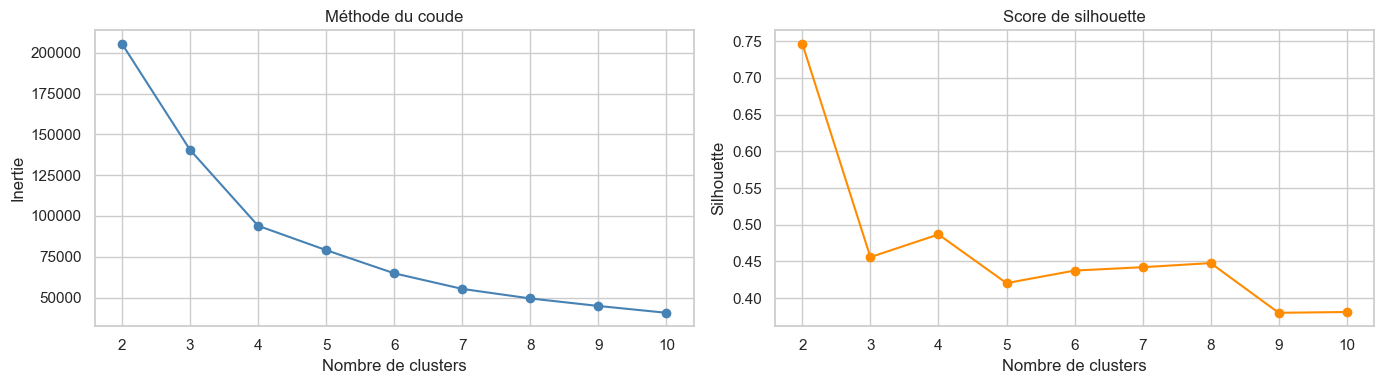

2     0.747
3     0.456
4     0.487
5     0.420
6     0.437
7     0.442
8     0.448
9     0.380
10    0.381
Name: Silhouette, dtype: float64

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

valeurs_k = range(2, 11)
inerties = []
silhouettes = []

debut = time()
for k in valeurs_k:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_1)
    inerties.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_1, kmeans.labels_, sample_size=10_000, random_state=0))
print(f"Temps de calcul : {time() - debut:.0f} secondes")

# Les deux graphiques côte à côte
fig, ax = plt.subplots(1, 2, figsize=(14, 4))

ax[0].plot(valeurs_k, inerties, marker='o', color='steelblue')
ax[0].set_title('Méthode du coude')
ax[0].set_xlabel('Nombre de clusters')
ax[0].set_ylabel('Inertie')

ax[1].plot(valeurs_k, silhouettes, marker='o', color='darkorange')
ax[1].set_title('Score de silhouette')
ax[1].set_xlabel('Nombre de clusters')
ax[1].set_ylabel('Silhouette')

plt.tight_layout()
plt.show()

# Les scores de silhouette en chiffres
pd.Series(silhouettes, index=valeurs_k, name='Silhouette').round(3)

In [5]:
# Taille et fréquence moyenne des 2 clusters
labels_k2 = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_1)
rfm.groupby(labels_k2)['Frequency'].agg(['count', 'mean']).round(2)

,count,mean
0,92091,1.00
1,2898,2.11


**À retenir :** le score de silhouette est le plus élevé pour **2 clusters** (0,75), mais ce
découpage ne fait que séparer les **92 091 clients qui ont commandé une seule fois** (97 %)
des **2 898 clients qui ont commandé plusieurs fois**. Or ces 92 091 clients ont des profils
très différents (clients récents ou anciens, petits ou gros paniers) : les mettre dans un
même segment empêcherait de leur adresser des campagnes adaptées.
On retient donc **4 clusters**, le meilleur score ensuite (0,49), qui correspond aussi au coude
de la courbe d'inertie.

#### Entraînement du modèle à 4 clusters

In [6]:
# Entraînement du K-Means à 4 clusters, avec mesure du temps
debut = time()
kmeans_1 = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X_1)
duree_1 = time() - debut
labels_1 = kmeans_1.labels_

print(f"Temps d'entraînement : {duree_1:.1f} secondes")

# Score de silhouette du modèle (estimé sur 10 000 clients)
silhouette_1 = silhouette_score(X_1, labels_1, sample_size=10_000, random_state=0)
print(f"Score de silhouette : {silhouette_1:.3f}")

# Profil moyen et taille de chaque cluster
profil_1 = rfm.groupby(labels_1)[variables_1].mean().round(1)
profil_1['Nombre de clients'] = pd.Series(labels_1).value_counts()
profil_1['Part (%)'] = (profil_1['Nombre de clients'] / len(rfm) * 100).round(1)
profil_1.index.name = 'Cluster'
profil_1

Temps d'entraînement : 2.6 secondes
Score de silhouette : 0.487


,Recency,Frequency,Monetary,Nombre de clients,Part (%)
Cluster,,,,,
0,133.5,1.0,134.5,51560,54.3
1,393.5,1.0,133.7,38072,40.1
2,226.6,2.1,289.1,2858,3.0
3,245.5,1.0,1156.2,2499,2.6


#### Description des clusters

- **Cluster 0 – Petits paniers récents** (51 560 clients, 54 %) : une seule commande, passée il y a
  environ 4 mois et demi (134 jours), pour 134 réals en moyenne.
- **Cluster 1 – Petits paniers anciens** (38 072 clients, 40 %) : le même profil d'achat,
  mais la commande date de plus d'un an (394 jours).
- **Cluster 2 – Clients fidèles** (2 858 clients, 3 %) : les seuls à avoir commandé plusieurs fois
  (2,1 commandes en moyenne), pour 289 réals au total.
- **Cluster 3 – Gros paniers** (2 499 clients, 2,6 %) : une seule commande, mais d'un montant
  très élevé (1 156 réals en moyenne).

**À retenir :** le modèle a un bon score de silhouette (0,49) et s'entraîne en moins d'une seconde.
Mais les clusters sont **très déséquilibrés** : 94 % des clients se retrouvent dans les deux
premiers, qui ne diffèrent que par leur **récence**. Les deux petits clusters isolent les clients
les plus intéressants (fidèles et gros paniers), mais ils ne représentent ensemble que 6 % de la base.

#### Visualisation des clusters

Pour chaque cluster : sa taille, puis la répartition de la récence, de la fréquence et du montant.
Les boîtes à moustaches sont tracées **sans les valeurs extrêmes**, pour rester lisibles.

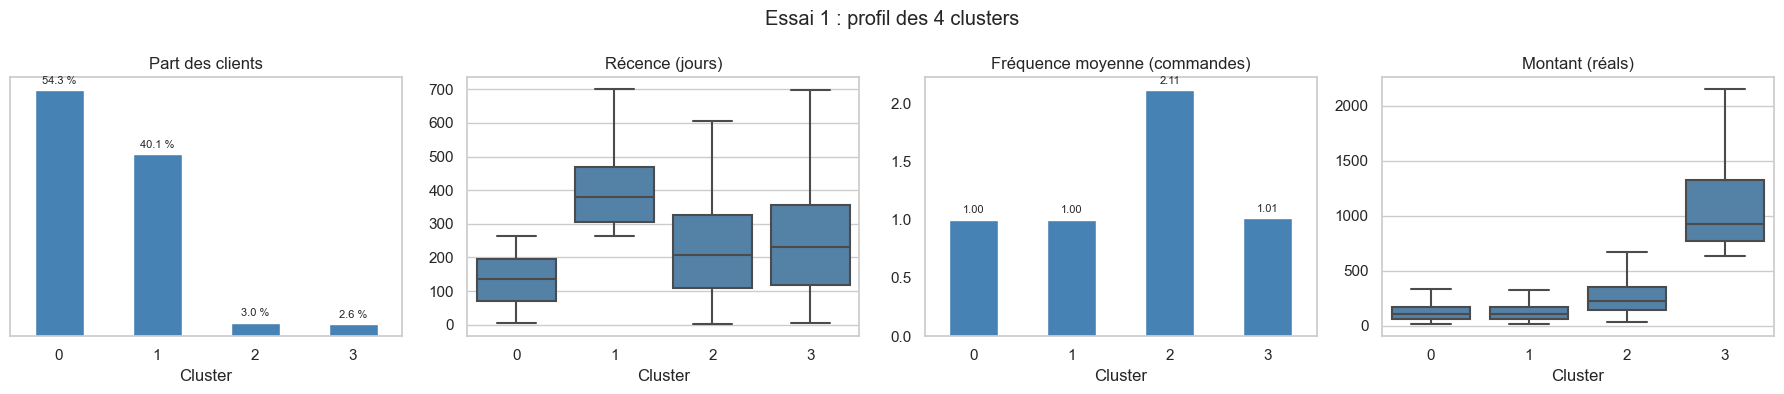

In [7]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))

# 1. Part des clients dans chaque cluster, en %
part = pd.Series(labels_1).value_counts(normalize=True).sort_index() * 100
part.plot.bar(color='steelblue', ax=ax[0])
ax[0].bar_label(ax[0].containers[0], fmt='%.1f %%', padding=3, fontsize=8)
ax[0].set_title('Part des clients')
ax[0].yaxis.set_visible(False)
ax[0].grid(False)   # supprime les lignes de grille

# 2. Récence : boîte à moustaches
sns.boxplot(x=labels_1, y=rfm['Recency'], showfliers=False, color='steelblue', ax=ax[1])
ax[1].set_title('Récence (jours)')

# 3. Fréquence : moyenne par cluster (les boîtes à moustaches seraient écrasées)
freq = rfm.groupby(labels_1)['Frequency'].mean()
freq.plot.bar(color='steelblue', ax=ax[2])
ax[2].bar_label(ax[2].containers[0], fmt='%.2f', padding=3, fontsize=8)
ax[2].set_title('Fréquence moyenne (commandes)')
ax[2].grid(False)

# 4. Montant : boîte à moustaches
sns.boxplot(x=labels_1, y=rfm['Monetary'], showfliers=False, color='steelblue', ax=ax[3])
ax[3].set_title('Montant (réals)')

# Mise en forme commune
for a in ax:
    a.set_xlabel('Cluster')
    a.set_ylabel('')
    a.tick_params(axis='x', labelrotation=0)

fig.suptitle('Essai 1 : profil des 4 clusters')
plt.tight_layout()
fig.savefig('images/kmeans_essai1.png', dpi=150, bbox_inches='tight')
plt.show()

<a href="#sommaire" rev="footnote">&#8617;</a>

### Essai 2 : RFM + note moyenne <a class="anchor" id="3_2"></a>

On ajoute la **note moyenne** que chaque client a donnée à ses commandes. Elle mesure sa
**satisfaction** et pourrait faire apparaître de nouveaux segments, par exemple les clients mécontents.

La note se trouve dans le fichier `data_commandes.csv` (une ligne par commande) : on calcule
la moyenne des notes de chaque client, puis on l'ajoute au tableau RFM.

In [8]:
# Fichier produit par le notebook 1 : une ligne par commande
commandes = pd.read_csv('data/data_commandes.csv')

# Note moyenne de chaque client
notes_clients = (commandes.groupby('customer_unique_id')
                 .agg(Review_score=('review_score', 'mean'))
                 .reset_index())

# Ajout au tableau RFM (un client = une ligne, d'où validate='one_to_one')
rfm = rfm.merge(notes_clients, on='customer_unique_id', how='left', validate='one_to_one')

print(f"Clients : {rfm.shape[0]:,}")
print(f"Clients sans note : {rfm['Review_score'].isnull().sum()}")
rfm['Review_score'].describe().round(2)

Clients : 94,989
Clients sans note : 0


count    94989.00
mean         4.12
std          1.31
min          1.00
25%          4.00
50%          5.00
75%          5.00
max          5.00
Name: Review_score, dtype: float64

#### Choix du nombre de clusters

On reprend la même méthode que pour l'essai 1. Pour ne pas répéter le code à chaque essai,
on la regroupe dans une **fonction**, `choisir_nombre_clusters`, réutilisée dans les essais suivants.

Temps de calcul : 110 secondes


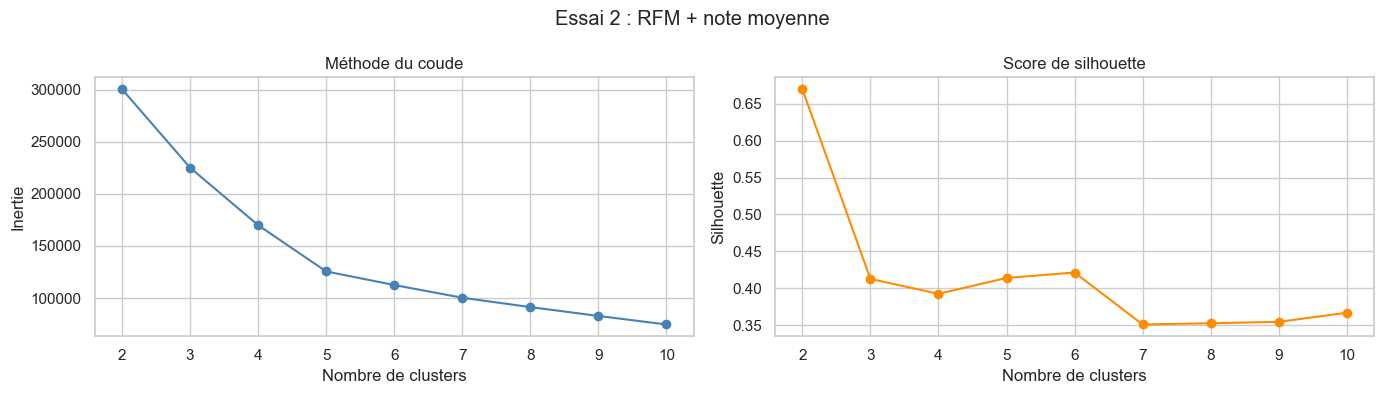

2     0.670
3     0.413
4     0.393
5     0.414
6     0.421
7     0.351
8     0.353
9     0.355
10    0.367
Name: Silhouette, dtype: float64

In [9]:
def choisir_nombre_clusters(X, titre):
    """Teste le K-Means de 2 à 10 clusters, trace la méthode du coude et le score de silhouette,
    puis renvoie les scores de silhouette."""
    valeurs_k = range(2, 11)
    inerties = []
    silhouettes = []

    debut = time()
    for k in valeurs_k:
        kmeans = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
        inerties.append(kmeans.inertia_)
        silhouettes.append(silhouette_score(X, kmeans.labels_, sample_size=10_000, random_state=0))
    print(f"Temps de calcul : {time() - debut:.0f} secondes")

    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(valeurs_k, inerties, marker='o', color='steelblue')
    ax[0].set_title('Méthode du coude')
    ax[0].set_xlabel('Nombre de clusters')
    ax[0].set_ylabel('Inertie')

    ax[1].plot(valeurs_k, silhouettes, marker='o', color='darkorange')
    ax[1].set_title('Score de silhouette')
    ax[1].set_xlabel('Nombre de clusters')
    ax[1].set_ylabel('Silhouette')

    fig.suptitle(titre)
    plt.tight_layout()
    plt.show()

    return pd.Series(silhouettes, index=valeurs_k, name='Silhouette').round(3)


# Essai 2 : standardisation des 4 variables, puis choix du nombre de clusters
variables_2 = ['Recency', 'Frequency', 'Monetary', 'Review_score']
X_2 = StandardScaler().fit_transform(rfm[variables_2])

choisir_nombre_clusters(X_2, 'Essai 2 : RFM + note moyenne')

**À retenir :** comme pour l'essai 1, le meilleur score est obtenu avec **2 clusters** (0,67),
un découpage trop grossier pour le marketing. Les scores de 3, 5 et 6 clusters sont ensuite
très proches (entre 0,41 et 0,42). On retient **5 clusters** : un score presque égal au meilleur,
qui correspond aussi au coude de la courbe d'inertie.

#### Entraînement du modèle à 5 clusters

In [10]:
# Entraînement du K-Means à 5 clusters, avec mesure du temps
debut = time()
kmeans_2 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_2)
duree_2 = time() - debut
labels_2 = kmeans_2.labels_

print(f"Temps d'entraînement : {duree_2:.1f} secondes")

# Score de silhouette du modèle (estimé sur 10 000 clients)
silhouette_2 = silhouette_score(X_2, labels_2, sample_size=10_000, random_state=0)
print(f"Score de silhouette : {silhouette_2:.3f}")

# Profil moyen et taille de chaque cluster
profil_2 = rfm.groupby(labels_2)[variables_2].mean().round(2)
profil_2['Nombre de clients'] = pd.Series(labels_2).value_counts()
profil_2['Part (%)'] = (profil_2['Nombre de clients'] / len(rfm) * 100).round(1)
profil_2.index.name = 'Cluster'
profil_2

Temps d'entraînement : 2.5 secondes
Score de silhouette : 0.414


,Recency,Frequency,Monetary,Review_score,Nombre de clients,Part (%)
Cluster,,,,,,
0,242.95,1.00,152.23,1.65,16250,17.1
1,226.62,2.11,289.05,4.18,2858,3.0
2,398.32,1.00,134.07,4.64,31838,33.5
3,127.38,1.00,132.93,4.69,41969,44.2
4,241.56,1.02,1249.65,4.05,2074,2.2


#### Description des clusters

- **Cluster 0 – Clients mécontents** (16 250 clients, 17 %) : une seule commande, il y a environ
  8 mois (243 jours), pour 152 réals, et une note moyenne très basse (1,65 sur 5).
- **Cluster 1 – Clients fidèles** (2 858 clients, 3 %) : les seuls à avoir commandé plusieurs fois
  (2,1 commandes en moyenne), pour 289 réals au total, et satisfaits (4,18 sur 5).
- **Cluster 2 – Petits paniers anciens** (31 838 clients, 34 %) : une seule commande, datant de plus
  d'un an (398 jours), pour 134 réals, et satisfaits (4,64 sur 5).
- **Cluster 3 – Petits paniers récents** (41 969 clients, 44 %) : une seule commande, passée il y a
  environ 4 mois (127 jours), pour 133 réals, et satisfaits (4,69 sur 5).
- **Cluster 4 – Gros paniers** (2 074 clients, 2 %) : une seule commande, mais d'un montant très
  élevé (1 250 réals en moyenne), et plutôt satisfaits (4,05 sur 5).

**À retenir :** la note fait apparaître un segment **nouveau et utile** : les **clients mécontents**,
soit environ un client sur six. C'est une cible naturelle pour le **service client**, par exemple
pour comprendre ce qui n'a pas fonctionné et éviter de perdre ces clients.
Les clusters sont un peu **plus équilibrés** que dans l'essai 1 (le plus gros réunit 44 % des
clients, contre 54 %), mais ils sont **moins bien séparés** : le score de silhouette passe
de 0,49 à 0,41. Les autres segments, eux, restent très proches de ceux de l'essai 1.

#### Visualisation des clusters

On regroupe le graphique de l'essai 1 dans une fonction, `afficher_clusters`, pour le réutiliser
à chaque essai. Elle affiche la taille de chaque cluster, la fréquence moyenne, puis la répartition
des autres variables (sans les valeurs extrêmes).

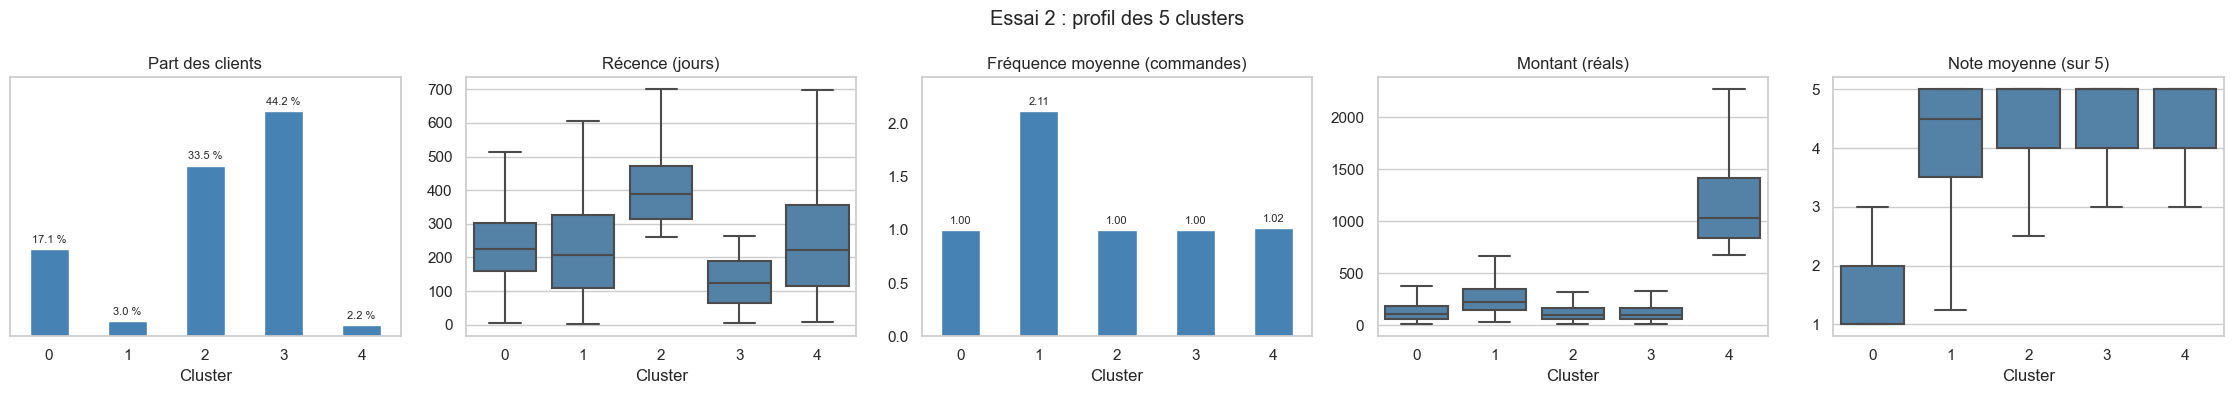

In [11]:
def afficher_clusters(labels, variables, titre, fichier):
    """Taille des clusters, fréquence moyenne et boîte à moustaches des autres variables."""
    titres = {'Recency': 'Récence (jours)', 'Frequency': 'Fréquence moyenne (commandes)',
              'Monetary': 'Montant (réals)', 'Review_score': 'Note moyenne (sur 5)',
              'N_products': 'Nombre de produits'}

    fig, ax = plt.subplots(1, len(variables) + 1, figsize=(4.5 * (len(variables) + 1), 4))

    # 1. Part des clients dans chaque cluster, en %
    part = pd.Series(labels).value_counts(normalize=True).sort_index() * 100
    part.plot.bar(color='steelblue', ax=ax[0])
    ax[0].bar_label(ax[0].containers[0], fmt='%.1f %%', padding=3, fontsize=8)
    ax[0].set_ylim(0, part.max() * 1.15)   # place au-dessus de la plus grande barre
    ax[0].set_title('Part des clients')
    ax[0].yaxis.set_visible(False)
    ax[0].grid(False)

    # 2. Une case par variable
    for a, var in zip(ax[1:], variables):
        if var == 'Frequency':
            # Fréquence : moyenne (les boîtes à moustaches seraient écrasées)
            freq = rfm.groupby(labels)[var].mean()
            freq.plot.bar(color='steelblue', ax=a)
            a.bar_label(a.containers[0], fmt='%.2f', padding=3, fontsize=8)
            a.set_ylim(0, freq.max() * 1.15)   # place au-dessus de la plus grande barre
            a.grid(False)
        else:
            sns.boxplot(x=labels, y=rfm[var], showfliers=False, color='steelblue', ax=a)
        a.set_title(titres[var])

    # Mise en forme commune
    for a in ax:
        a.set_xlabel('Cluster')
        a.set_ylabel('')
        a.tick_params(axis='x', labelrotation=0)

    fig.suptitle(titre)
    plt.tight_layout()
    fig.savefig(f'images/{fichier}', dpi=150, bbox_inches='tight')
    plt.show()


afficher_clusters(labels_2, variables_2, 'Essai 2 : profil des 5 clusters', 'kmeans_essai2.png')

Le graphique confirme le tableau : le **cluster 0** se distingue uniquement par sa **note**,
entre 1 et 3, alors que les clients des autres clusters notent presque tous entre 4 et 5.

<a href="#sommaire" rev="footnote">&#8617;</a>

### Essai 3 : RFM + note moyenne + nombre de produits <a class="anchor" id="3_3"></a>

On ajoute enfin le **nombre total de produits** achetés par chaque client, calculé à partir
du fichier des commandes.

In [12]:
# Nombre total de produits achetés par chaque client
produits_clients = (commandes.groupby('customer_unique_id')
                    .agg(N_products=('n_produits', 'sum'))
                    .reset_index())

rfm = rfm.merge(produits_clients, on='customer_unique_id', how='left', validate='one_to_one')

print(f"Clients : {rfm.shape[0]:,}")
print(f"Clients sans nombre de produits : {rfm['N_products'].isnull().sum()}")
rfm['N_products'].value_counts().sort_index().head(6)

Clients : 94,989
Clients sans nombre de produits : 0


0        7
1    83179
2     8950
3     1666
4      629
5      246
Name: N_products, dtype: int64

**88 % des clients** n'ont acheté qu'un seul produit. Comme la fréquence, cette variable varie
donc peu d'un client à l'autre : elle risque d'apporter peu d'information à la segmentation.

Temps de calcul : 140 secondes


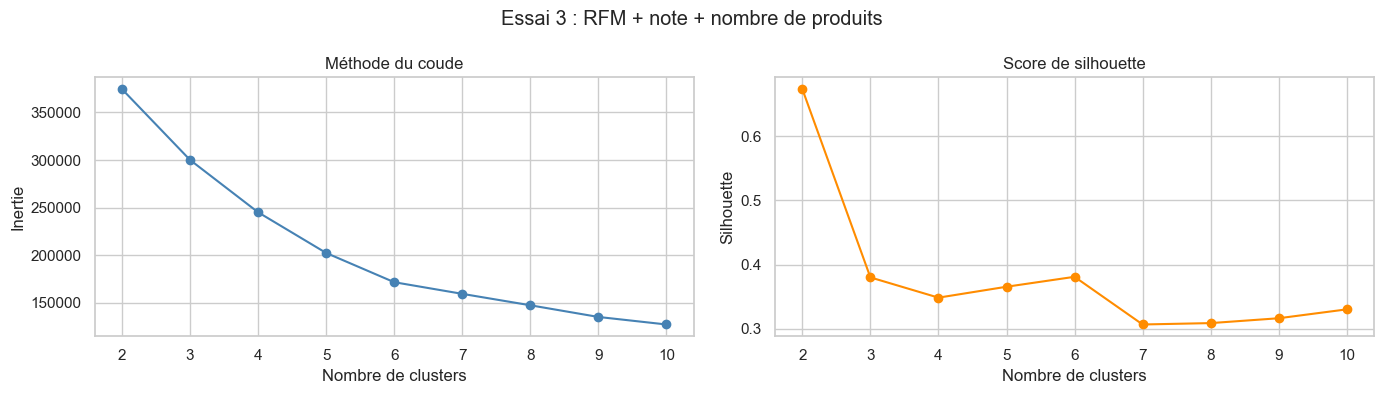

2     0.673
3     0.380
4     0.348
5     0.365
6     0.381
7     0.307
8     0.309
9     0.316
10    0.330
Name: Silhouette, dtype: float64

In [13]:
variables_3 = ['Recency', 'Frequency', 'Monetary', 'Review_score', 'N_products']
X_3 = StandardScaler().fit_transform(rfm[variables_3])

choisir_nombre_clusters(X_3, 'Essai 3 : RFM + note + nombre de produits')

#### Entraînement du modèle

In [14]:
K_3 = 6

debut = time()
kmeans_3 = KMeans(n_clusters=K_3, n_init=10, random_state=0).fit(X_3)
duree_3 = time() - debut
labels_3 = kmeans_3.labels_

print(f"Temps d'entraînement : {duree_3:.1f} secondes")

silhouette_3 = silhouette_score(X_3, labels_3, sample_size=10_000, random_state=0)
print(f"Score de silhouette : {silhouette_3:.3f}")

profil_3 = rfm.groupby(labels_3)[variables_3].mean().round(2)
profil_3['Nombre de clients'] = pd.Series(labels_3).value_counts()
profil_3['Part (%)'] = (profil_3['Nombre de clients'] / len(rfm) * 100).round(1)
profil_3.index.name = 'Cluster'
profil_3

Temps d'entraînement : 3.8 secondes
Score de silhouette : 0.381


,Recency,Frequency,Monetary,Review_score,N_products,Nombre de clients,Part (%)
Cluster,,,,,,,
0,240.45,1.02,343.62,3.42,3.94,2013,2.1
1,241.20,1.01,1273.15,4.11,1.17,1871,2.0
2,227.09,2.12,284.61,4.19,2.47,2821,3.0
3,127.53,1.00,131.32,4.69,1.06,41340,43.5
4,243.10,1.00,146.56,1.66,1.14,15607,16.4
5,398.32,1.00,132.31,4.64,1.07,31337,33.0


Les clusters de cet essai étant très proches de ceux de l'essai 2, on ne les décrit pas en détail.

**À retenir :** comme pour les essais précédents, le meilleur score est obtenu avec **2 clusters**,
un découpage trop grossier. On retient **6 clusters** : c'est le coude de la courbe d'inertie,
et le meilleur score de silhouette ensuite (0,381).
Les scores sont **plus faibles que pour les essais 1 et 2** : ajouter le nombre de produits,
qui varie très peu d'un client à l'autre, rend les clusters moins bien séparés.

<a href="#sommaire" rev="footnote">&#8617;</a>

### Essai 4 : logarithme du RFM <a class="anchor" id="3_4"></a>

Dans les essais précédents, les quelques clients qui dépensent énormément forment un cluster
à eux seuls, pendant que la grande majorité des clients se partage un ou deux énormes clusters.
Comme vu dans le notebook 1, le **logarithme** réduit l'écart entre les grandes valeurs :
les distances reflètent alors mieux les **différences de comportement** de la majorité des clients.

Temps de calcul : 141 secondes


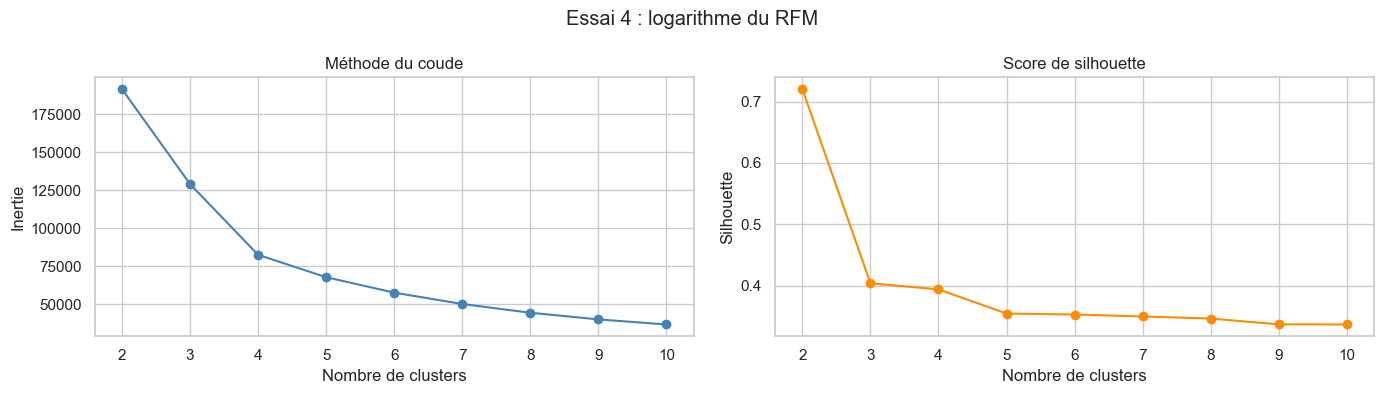

2     0.720
3     0.404
4     0.394
5     0.355
6     0.353
7     0.350
8     0.346
9     0.337
10    0.337
Name: Silhouette, dtype: float64

In [15]:
# Logarithme des trois indicateurs (toutes les valeurs sont >= 1)
for col in ['Recency', 'Frequency', 'Monetary']:
    rfm[f'log_{col}'] = np.log(rfm[col])

variables_4 = ['log_Recency', 'log_Frequency', 'log_Monetary']
X_4 = StandardScaler().fit_transform(rfm[variables_4])

choisir_nombre_clusters(X_4, 'Essai 4 : logarithme du RFM')

**À retenir :** comme pour les autres essais, le meilleur score est obtenu avec **2 clusters** (0,72),
un découpage trop grossier. On retient **4 clusters** : le coude de la courbe d'inertie y est
très net, et le score de silhouette (0,394) est presque égal à celui de 3 clusters (0,404),
tout en donnant un segment de plus pour cibler les campagnes.

#### Entraînement du modèle

In [16]:
K_4 = 4   

debut = time()
kmeans_4 = KMeans(n_clusters=K_4, n_init=10, random_state=0).fit(X_4)
duree_4 = time() - debut
labels_4 = kmeans_4.labels_

print(f"Temps d'entraînement : {duree_4:.1f} secondes")

silhouette_4 = silhouette_score(X_4, labels_4, sample_size=10_000, random_state=0)
print(f"Score de silhouette : {silhouette_4:.3f}")

# Profil décrit avec les valeurs d'origine (jours, réals), plus parlantes que les logarithmes
profil_4 = rfm.groupby(labels_4)[variables_1].mean().round(2)
profil_4['Nombre de clients'] = pd.Series(labels_4).value_counts()
profil_4['Part (%)'] = (profil_4['Nombre de clients'] / len(rfm) * 100).round(1)
profil_4.index.name = 'Cluster'
profil_4

Temps d'entraînement : 0.9 secondes
Score de silhouette : 0.394


,Recency,Frequency,Monetary,Nombre de clients,Part (%)
Cluster,,,,,
0,49.92,1.00,133.99,17433,18.4
1,295.98,1.00,67.80,42050,44.3
2,226.50,2.11,308.36,2888,3.0
3,280.64,1.00,296.21,32618,34.3


#### Description des clusters

- **Cluster 0 – Nouveaux clients** (17 433 clients, 18 %) : une seule commande, passée il y a
  moins de 2 mois (50 jours en moyenne), pour 134 réals.
- **Cluster 1 – Petits paniers** (42 050 clients, 44 %) : une seule commande, il y a environ
  10 mois (296 jours), pour un petit montant (68 réals).
- **Cluster 2 – Clients fidèles** (2 888 clients, 3 %) : les seuls à avoir commandé plusieurs fois
  (2,1 commandes en moyenne), pour 308 réals au total.
- **Cluster 3 – Gros paniers ponctuels** (32 618 clients, 34 %) : une seule commande, il y a environ
  9 mois (281 jours), mais pour un montant élevé (296 réals, soit plus de 4 fois le cluster 1).

**À retenir :** le cluster des **clients fidèles** reste petit (3 %), car seuls 3 % des clients
ont commandé plus d'une fois : c'est la réalité des données, et non un défaut du modèle.
En revanche, le logarithme répartit **beaucoup mieux les 97 % restants** : au lieu d'un énorme
cluster de petits paniers récents (54 % dans l'essai 1) et d'un tout petit cluster de très gros
paniers (2,6 %), on obtient trois groupes de taille comparable (18 %, 34 % et 44 %), qui
correspondent chacun à un **comportement clair** et à une **action marketing** différente.
Le score de silhouette (0,39) est plus faible que celui de l'essai 1 (0,49), mais ces segments
sont **beaucoup plus faciles à exploiter**.

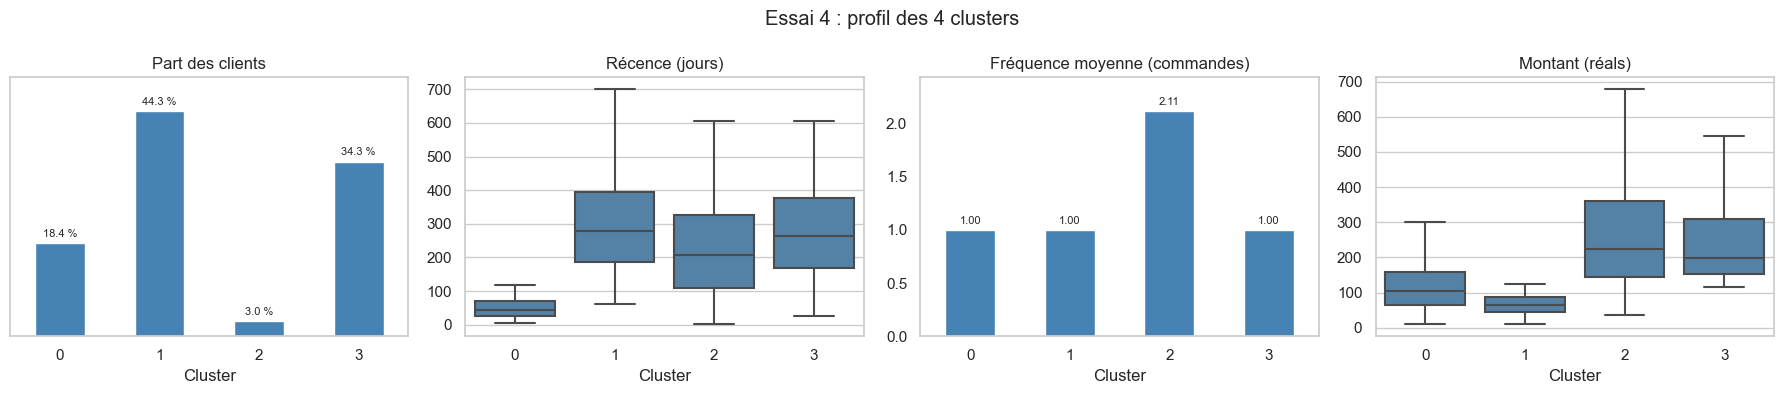

In [17]:
# Graphique avec les valeurs d'origine (variables_1), plus faciles à lire que les logarithmes
afficher_clusters(labels_4, variables_1, f'Essai 4 : profil des {K_4} clusters', 'kmeans_essai4.png')

Le graphique montre ce qui distingue chaque cluster : la **récence** pour le cluster 0 (presque
toutes ses commandes ont moins de 4 mois), le **montant** pour les clusters 1 et 3 (leurs montants
se chevauchent à peine), et la **fréquence** pour le cluster 2.

#### Distance entre les clusters

Chaque cercle représente un cluster : sa **taille** indique le nombre de clients, et sa **position**
celle du centre du cluster, projetée en 2 dimensions. Cette projection déforme un peu les distances :
le graphique donne une idée générale de l'éloignement des clusters, sans être une mesure exacte.

C:\Users\modes\anaconda3\lib\site-packages\sklearn\manifold\_mds.py:299: FutureWarning: The default value of `normalized_stress` will change to `'auto'` in version 1.4. To suppress this warning, manually set the value of `normalized_stress`.
  warnings.warn(


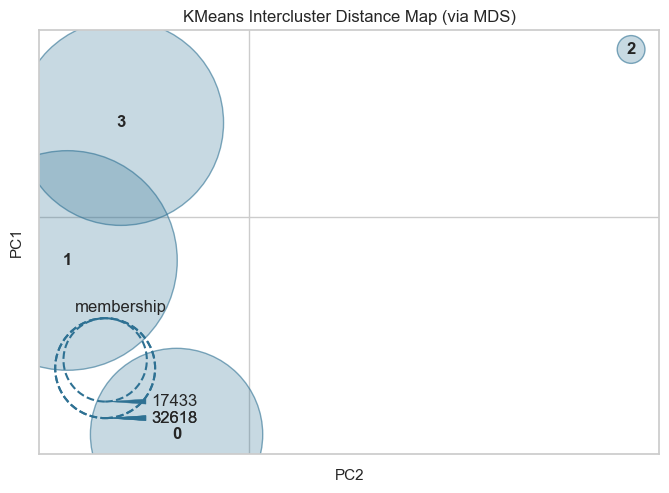

<AxesSubplot: title={'center': 'KMeans Intercluster Distance Map (via MDS)'}, xlabel='PC2', ylabel='PC1'>

In [18]:
#Cette cellule utilise la bibliothèque **yellowbrick** : si elle n'est pas installée,
#lancer `pip install yellowbrick`.*
from yellowbrick.cluster import InterclusterDistance 

visualizer = InterclusterDistance(KMeans(n_clusters=K_4, n_init=10, random_state=0))
visualizer.fit(X_4)
visualizer.show()

**À retenir :** la carte confirme le profil des clusters. Les clusters **1 et 3** sont proches,
car ils ne diffèrent que par le montant. Le cluster **0** (nouveaux clients) est bien séparé
par sa récence, et le petit cluster **2** (clients fidèles) est très éloigné de tous les autres :
ce sont les seuls clients qui ont commandé plusieurs fois.

<a href="#sommaire" rev="footnote">&#8617;</a>

## DBSCAN <a class="anchor" id="4"></a>

**DBSCAN** fonctionne autrement que le K-Means : il cherche les **zones où les clients sont très
rapprochés** et ne fixe pas le nombre de clusters à l'avance. Les clients isolés sont classés
comme **bruit** (étiquette -1). Pour en savoir plus :
[documentation de DBSCAN (scikit-learn)](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html).

DBSCAN a deux réglages :
- `eps` : la distance maximale entre deux clients pour qu'ils soient considérés comme voisins ;
- `min_samples` : le nombre minimal de voisins pour former un groupe dense.

On teste plusieurs combinaisons sur le RFM standardisé de l'essai 1. DBSCAN étant très
**gourmand en mémoire**, on l'applique à un **échantillon de 20 000 clients**.

In [19]:
from sklearn.cluster import DBSCAN
from itertools import product

# Échantillon de 20 000 clients, tirés au hasard (les mêmes pour tous les réglages)
rng = np.random.default_rng(0)
idx_echantillon = rng.choice(len(X_1), size=20_000, replace=False)
X_ech = X_1[idx_echantillon]

essais_dbscan = []
debut = time()
for eps, min_samples in product([0.1, 0.2, 0.3, 0.5], [20, 50, 100]):
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_ech)
    essais_dbscan.append({
        'eps': eps,
        'min_samples': min_samples,
        'Clusters': len(set(labels)) - (-1 in labels),   # le bruit (-1) n'est pas un cluster
        'Bruit (%)': round((labels == -1).mean() * 100, 1)
    })
print(f"Temps de calcul : {time() - debut:.0f} secondes")

essais_dbscan = pd.DataFrame(essais_dbscan)

# Nombre de clusters (en haut) et part de bruit (en bas) pour chaque réglage
display(essais_dbscan.pivot(index='min_samples', columns='eps', values='Clusters'))
display(essais_dbscan.pivot(index='min_samples', columns='eps', values='Bruit (%)'))

Temps de calcul : 66 secondes


eps,0.1,0.2,0.3,0.5
min_samples,,,,
20,5,6,3,3
50,1,1,2,2
100,1,1,1,2


eps,0.1,0.2,0.3,0.5
min_samples,,,,
20,10.3,4.7,2.8,1.4
50,16.2,8.8,5.6,2.6
100,24.4,11.0,8.0,3.9


**À retenir :** avec la plupart des réglages, DBSCAN ne trouve que **1 à 3 clusters**. Pour en
obtenir davantage, il faut réduire `min_samples`, mais une partie des clients est alors classée
en bruit. On examine le réglage qui donne le plus de clusters avec peu de bruit :
`eps = 0.2` et `min_samples = 20` (6 clusters, 4,7 % de bruit).

#### Profil des clusters du réglage retenu

In [20]:
EPS, MIN_SAMPLES = 0.2, 20

debut = time()
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_ech)
duree_db = time() - debut
print(f"Temps d'entraînement : {duree_db:.1f} secondes")

# Profil des clusters, avec les valeurs d'origine des clients de l'échantillon
rfm_ech = rfm.iloc[idx_echantillon]
profil_db = rfm_ech.groupby(labels_db)[variables_1].mean().round(1)
profil_db['Nombre de clients'] = pd.Series(labels_db).value_counts()
profil_db['Part (%)'] = (profil_db['Nombre de clients'] / len(labels_db) * 100).round(1)
profil_db.index.name = 'Cluster (-1 = bruit)'
profil_db

Temps d'entraînement : 3.7 secondes


,Recency,Frequency,Monetary,Nombre de clients,Part (%)
Cluster (-1 = bruit),,,,,
-1,271.8,1.5,806.0,940,4.7
0,242.3,1.0,133.3,18826,94.1
1,186.7,2.0,227.6,65,0.3
2,696.7,1.0,94.0,45,0.2
3,103.1,2.0,159.1,59,0.3
4,286.6,2.0,155.4,50,0.2
5,225.7,2.0,105.9,15,0.1


**À retenir :** DBSCAN n'est **pas adapté** à ces données :
- un seul cluster regroupe **94 % des clients** : c'est presque comme s'il n'y avait pas de segmentation ;
- les 5 autres clusters sont **minuscules** (de 15 à 65 clients chacun) ;
- les clients classés en **bruit** (4,7 %) sont justement les **plus intéressants pour le marketing** :
  ils ont dépensé 806 réals en moyenne, soit 6 fois plus que le grand cluster, et commandé
  plus souvent.

Ce résultat suggère que les clients d'Olist ne forment pas de **groupes denses bien séparés** :
la plupart sont rapprochés les uns des autres, et seuls les clients atypiques (gros paniers,
commandes multiples) s'en éloignent. DBSCAN est donc écarté.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Classification ascendante hiérarchique (CAH) <a class="anchor" id="5"></a>

La **CAH** part de clusters d'un seul client, puis **fusionne pas à pas les deux groupes les plus
proches**, jusqu'à n'en avoir plus qu'un. Le **dendrogramme** montre ces fusions successives et aide
à choisir le nombre de clusters. On utilise la méthode de **Ward**, qui fusionne à chaque étape
les deux groupes dont la réunion augmente le moins la dispersion.

La CAH calcule les distances entre **toutes les paires de clients** : dans la version précédente
de ce notebook, le calcul sur 70 000 clients prenait plus de 20 minutes. On l'applique donc au
**même échantillon de 20 000 clients** que DBSCAN.

Temps de calcul : 86 secondes


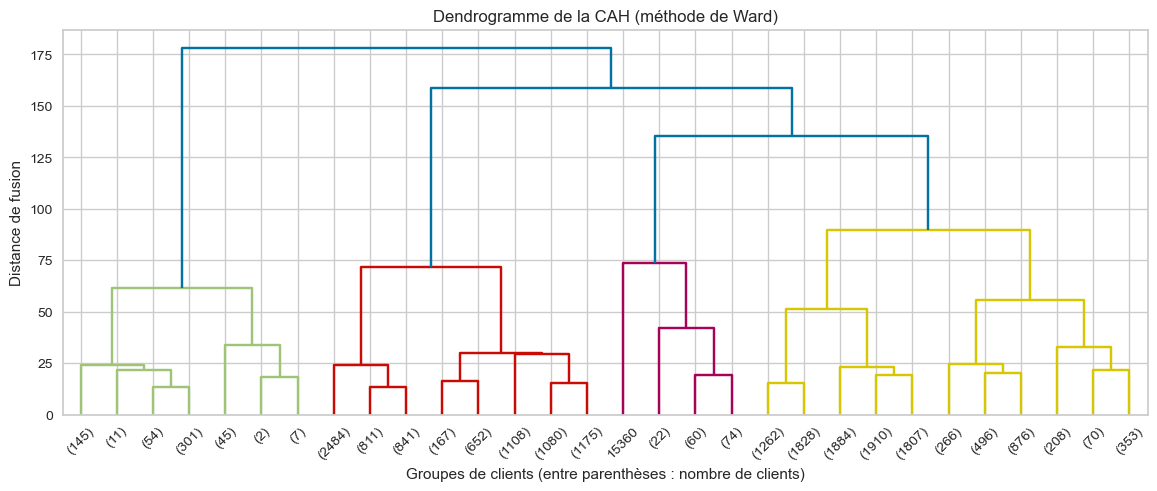

In [21]:
from scipy.cluster.hierarchy import dendrogram, linkage

debut = time()
Z = linkage(X_ech, method='ward')
print(f"Temps de calcul : {time() - debut:.0f} secondes")

fig, ax = plt.subplots(figsize=(14, 5))
# Seules les 30 dernières fusions sont affichées, pour la lisibilité
dendrogram(Z, truncate_mode='lastp', p=30, ax=ax)
ax.set_title('Dendrogramme de la CAH (méthode de Ward)')
ax.set_xlabel('Groupes de clients (entre parenthèses : nombre de clients)')
ax.set_ylabel('Distance de fusion')
plt.show()

**À retenir :** pour choisir le nombre de clusters, on cherche sur le dendrogramme le **plus grand
écart vertical sans fusion**. Il se situe entre les hauteurs 90 et 135 environ : en coupant
l'arbre à ce niveau, la ligne de coupe traverse **4 branches**, ce qui donne **4 clusters**
(les 4 couleurs du graphique).
Leurs tailles sont très inégales : deux grands groupes réunissent 96 % des clients,
comme dans l'essai 1 du K-Means.

#### Entraînement du modèle à 4 clusters

In [22]:
from sklearn.cluster import AgglomerativeClustering

K_CAH = 4

debut = time()
labels_cah = AgglomerativeClustering(n_clusters=K_CAH, linkage='ward').fit_predict(X_ech)
duree_cah = time() - debut
print(f"Temps d'entraînement : {duree_cah:.1f} secondes")

silhouette_cah = silhouette_score(X_ech, labels_cah, sample_size=10_000, random_state=0)
print(f"Score de silhouette : {silhouette_cah:.3f}")

profil_cah = rfm_ech.groupby(labels_cah)[variables_1].mean().round(1)
profil_cah['Nombre de clients'] = pd.Series(labels_cah).value_counts()
profil_cah['Part (%)'] = (profil_cah['Nombre de clients'] / len(labels_cah) * 100).round(1)
profil_cah.index.name = 'Cluster'
profil_cah

Temps d'entraînement : 104.5 secondes
Score de silhouette : 0.451


,Recency,Frequency,Monetary,Nombre de clients,Part (%)
Cluster,,,,,
0,137.9,1.0,164.5,10960,54.8
1,273.5,1.0,1898.4,157,0.8
2,385.0,1.0,124.7,8318,41.6
3,224.1,2.1,295.8,565,2.8


**À retenir :** la CAH retrouve des clusters **très proches de ceux de l'essai 1 du K-Means** :
deux grands groupes de petits paniers, séparés par leur récence (97 % des clients à eux deux),
les clients fidèles (2,8 %) et un tout petit groupe de très gros paniers (0,8 %).
Son score de silhouette est bon (0,45), mais elle a deux inconvénients majeurs :
- elle est **très lente** : 63 secondes pour 20 000 clients seulement, contre moins d'une seconde
  pour le K-Means sur les 94 989 clients. Sur toute la base, le calcul prendrait bien plus longtemps ;
- elle ne permet pas de **classer directement un nouveau client** : il faudrait refaire tout
  le calcul, alors que le K-Means le rattache simplement au centre le plus proche.

Pour une segmentation à mettre à jour régulièrement, la CAH est donc écartée.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Choix du modèle <a class="anchor" id="6"></a>

On compare les modèles sur trois critères :
- la **séparation des groupes** : le score de silhouette (plus il est élevé, mieux c'est) ;
- l'**équilibre des groupes** : la part du plus gros cluster (plus elle est faible, plus les
  clients sont répartis entre plusieurs segments) ;
- le **temps d'entraînement**.

DBSCAN n'apparaît pas dans le tableau : il a déjà été écarté, car il réunit 94 % des clients
dans un seul cluster.

In [23]:
def part_plus_gros(labels):
    """Part des clients (en %) dans le plus gros cluster."""
    return round(pd.Series(labels).value_counts(normalize=True).max() * 100, 1)


comparaison = pd.DataFrame({
    'Modèle': ['K-Means 1', 'K-Means 2', 'K-Means 3', 'K-Means 4', 'CAH'],
    'Variables': ['R, F, M', 'R, F, M + note', 'R, F, M + note + produits',
                  'log(R, F, M)', 'R, F, M (échantillon)'],
    'Clusters': [4, 5, K_3, K_4, K_CAH],
    'Silhouette': [silhouette_1, silhouette_2, silhouette_3, silhouette_4, silhouette_cah],
    'Plus gros cluster (%)': [part_plus_gros(l) for l in
                              [labels_1, labels_2, labels_3, labels_4, labels_cah]],
    'Temps (s)': [duree_1, duree_2, duree_3, duree_4, duree_cah],
}).round({'Silhouette': 3, 'Temps (s)': 1})

comparaison

,Modèle,Variables,Clusters,Silhouette,Plus gros cluster (%),Temps (s)
0,K-Means 1,"R, F, M",4,0.487,54.3,2.6
1,K-Means 2,"R, F, M + note",5,0.414,44.2,2.5
2,K-Means 3,"R, F, M + note + produits",6,0.381,43.5,3.8
3,K-Means 4,"log(R, F, M)",4,0.394,44.3,0.9
4,CAH,"R, F, M (échantillon)",4,0.451,54.8,104.5


**Décision : on retient le K-Means de l'essai 2** (RFM + note moyenne, 5 clusters).

- L'**essai 1** a le meilleur score de silhouette (0,49), mais son plus gros cluster réunit 54 %
  des clients : il ne permettrait pas de cibler les campagnes.
- Les **essais 2 et 4** donnent des clusters aussi équilibrés l'un que l'autre (44 % pour le plus
  gros). L'essai 2 a un meilleur score de silhouette (0,41 contre 0,39), et il fait apparaître
  un segment que les autres essais ne donnent pas : les **clients mécontents** (17 %).
- L'**essai 3** n'apporte rien de plus que l'essai 2 : le nombre de produits varie trop peu
  d'un client à l'autre.
- La **CAH** est écartée, car elle est beaucoup trop lente pour une segmentation à mettre
  à jour régulièrement.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Stabilité du modèle retenu <a class="anchor" id="7"></a>

Le K-Means part de **centres choisis au hasard**. Un modèle fiable doit donner **les mêmes segments**
quel que soit ce point de départ.

On entraîne donc le modèle **10 fois avec des points de départ différents** (paramètre `random_state`),
et on compare chaque résultat au modèle retenu avec l'**ARI** (*Adjusted Rand Index*). L'ARI vaut
**1** si les deux segmentations sont identiques, et **0** si elles n'ont pas plus de points communs
qu'un découpage au hasard.

In [24]:
from sklearn.metrics import adjusted_rand_score

scores_ari = []
for graine in range(1, 11):
    labels_test = KMeans(n_clusters=5, n_init=1, random_state=graine).fit_predict(X_2)
    scores_ari.append(adjusted_rand_score(labels_2, labels_test))

stabilite = pd.Series(scores_ari, index=range(1, 11), name='ARI').round(3)
stabilite.index.name = 'Point de départ'

print(f"ARI moyen : {stabilite.mean():.3f} (minimum : {stabilite.min():.3f})")
stabilite.to_frame().T

ARI moyen : 0.995 (minimum : 0.960)


Point de départ,1,2,3,4,5,6,7,8,9,10
ARI,0.999,0.999,0.999,1.0,1.0,0.995,0.999,0.998,0.96,0.999


**À retenir :** l'ARI est **proche de 1** pour les 10 points de départ (0,995 en moyenne,
0,96 au minimum) : le modèle retrouve **les mêmes segments** quel que soit son point de départ.
La segmentation est donc **stable et reproductible**.

La stabilité **dans le temps**, à mesure que de nouveaux clients arrivent, sera étudiée dans
le notebook 3 : elle permettra de fixer la fréquence de mise à jour de la segmentation.

<a href="#sommaire" rev="footnote">&#8617;</a>

## Conclusion <a class="anchor" id="8"></a>

**Ce qui a été fait :**
- une première approche par **scores RFM**, simple mais limitée : elle classe les clients
  du moins bon au meilleur, sans faire apparaître de comportements différents ;
- **3 algorithmes** comparés (K-Means, DBSCAN, CAH) et **4 jeux de variables** testés pour le K-Means ;
- **DBSCAN** écarté, car il réunit 94 % des clients dans un seul cluster, et la **CAH** écartée,
  car elle est trop lente pour une segmentation à mettre à jour régulièrement.

**Le modèle retenu :** un **K-Means à 5 clusters** sur la récence, la fréquence, le montant et
la note moyenne. Il donne des segments **équilibrés, stables** et **faciles à exploiter** :

| Segment | Part des clients | Action marketing possible |
|---|---|---|
| Petits paniers récents | 44 % | Offre sur la deuxième commande |
| Petits paniers anciens | 34 % | Campagne de réactivation à faible coût |
| Clients mécontents | 17 % | Contact par le service client |
| Clients fidèles | 3 % | Programme de fidélité |
| Gros paniers | 2 % | Relance personnalisée |

**Le message clé pour Olist :** 97 % des clients n'ont commandé **qu'une seule fois**.
L'enjeu prioritaire n'est donc pas d'attirer de nouveaux clients, mais de **les faire revenir**,
en commençant par les 17 % de clients mécontents.

**Prochaine étape (notebook 3) :** déterminer **combien de temps la segmentation reste valable**,
pour proposer une fréquence de mise à jour.

<a href="#sommaire" rev="footnote">&#8617;</a>